# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in `Samoa.json`).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [1]:
from utils.config import (
    PATHS,
    SIMULATIONS,
    get_offshore_wave,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils.simulation.offshore_forcing import boundary_parameters
from utils.simulation.snapwave_wrappers import SnapWaveDynamicModelWrapper

## Configuration

In [2]:
offshore_name = "WHACS"  # must match an entry in Samoa.json → offshore_waves
period = "2020"  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
templates_dir = resolve(SIMULATIONS["dynamic_templates"])
cases_dir = resolve(SIMULATIONS["dynamic_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])
raw_goals = load_goals()

print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"period    : {period}")

offshore  : WHACS → /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/WHACS/processed/Samoa_WHACS_goal.zarr
goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-dynamic
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
period    : 2020


## Offshore waves → boundary forcing

In [3]:
offshore_ds = open_offshore_waves(entry=offshore_entry).sel(time=period).load()
offshore_ds

<xarray.Dataset> Size: 23MB
Dimensions:   (time: 8784, goal: 16)
Coordinates:
  * time      (time) datetime64[ns] 70kB 2020-01-01 ... 2020-12-31T23:00:00
  * goal      (goal) int64 128B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16
    seapoint  (goal) int64 128B 970691 971044 971049 ... 969892 970007 970352
Data variables: (12/20)
    dir       (time, goal) float64 1MB 263.6 271.9 294.4 ... 187.5 195.5 347.7
    hs        (time, goal) float64 1MB 2.787 2.787 2.557 ... 0.9336 0.9439 1.027
    pdir0     (time, goal) float64 1MB 258.5 265.1 287.2 302.5 ... nan 93.8 nan
    pdir1     (time, goal) float64 1MB 53.5 56.2 55.9 55.3 ... 191.3 191.3 27.9
    pdir2     (time, goal) float64 1MB 343.7 342.6 342.9 ... 219.6 219.7 215.6
    pdir3     (time, goal) float64 1MB 339.5 338.7 118.7 ... 80.9 186.4 347.7
    ...        ...
    ptp0      (time, goal) float64 1MB 7.7 7.65 7.59 7.64 ... nan nan 8.33 nan
    ptp1      (time, goal) float64 1MB 9.93 9.85 9.83 9.84 ... 12.11 12.09 7.96
    ptp2      (time, goal) float64 1MB 12.19 12.13 12.06 ... 11.48 11.52 11.48
    ptp3      (time, goal) float64 1MB 23.64 23.39 11.03 ... 7.74 7.02 11.03
    spr       (time, goal) float64 1MB 53.6 52.2 45.6 43.4 ... 54.2 59.0 71.6
    tp        (time, goal) float64 1MB 7.812 7.752 7.634 ... 12.05 11.76 11.36
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [4]:
metamodel_parameters = boundary_parameters(offshore_ds)
list(metamodel_parameters.keys())

['hs_goals', 'tp_goals', 'dir_goals', 'spr_goals', 'tref']

In [5]:
import numpy as np

n_cases = len(metamodel_parameters["tref"])
metamodel_parameters["save_map"] = np.random.choice(
    [True, False], size=n_cases, p=[0.05, 0.95]
).tolist()
sum(metamodel_parameters["save_map"]), n_cases

(442, 8784)

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + observed direction-range bars per goal; right side = text summary.
Each case is one timestep with **all goals forced** on the boundary.
Review this before `build_cases()`.

In [6]:
wrapper = SnapWaveDynamicModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-07-29 09:13:54,430 - SnapWaveDynamicModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-07-29 09:13:54,431 - SnapWaveDynamicModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-07-29 09:13:54,431 - SnapWaveDynamicModelWrapper - WARNING - Parameter dir_goals is not in the default_parameters
2026-07-29 09:13:54,431 - SnapWaveDynamicModelWrapper - WARNING - Parameter spr_goals is not in the default_parameters
2026-07-29 09:13:54,432 - SnapWaveDynamicModelWrapper - WARNING - Parameter tref is not in the default_parameters
2026-07-29 09:13:54,432 - SnapWaveDynamicModelWrapper - WARNING - Parameter save_map is not in the default_parameters


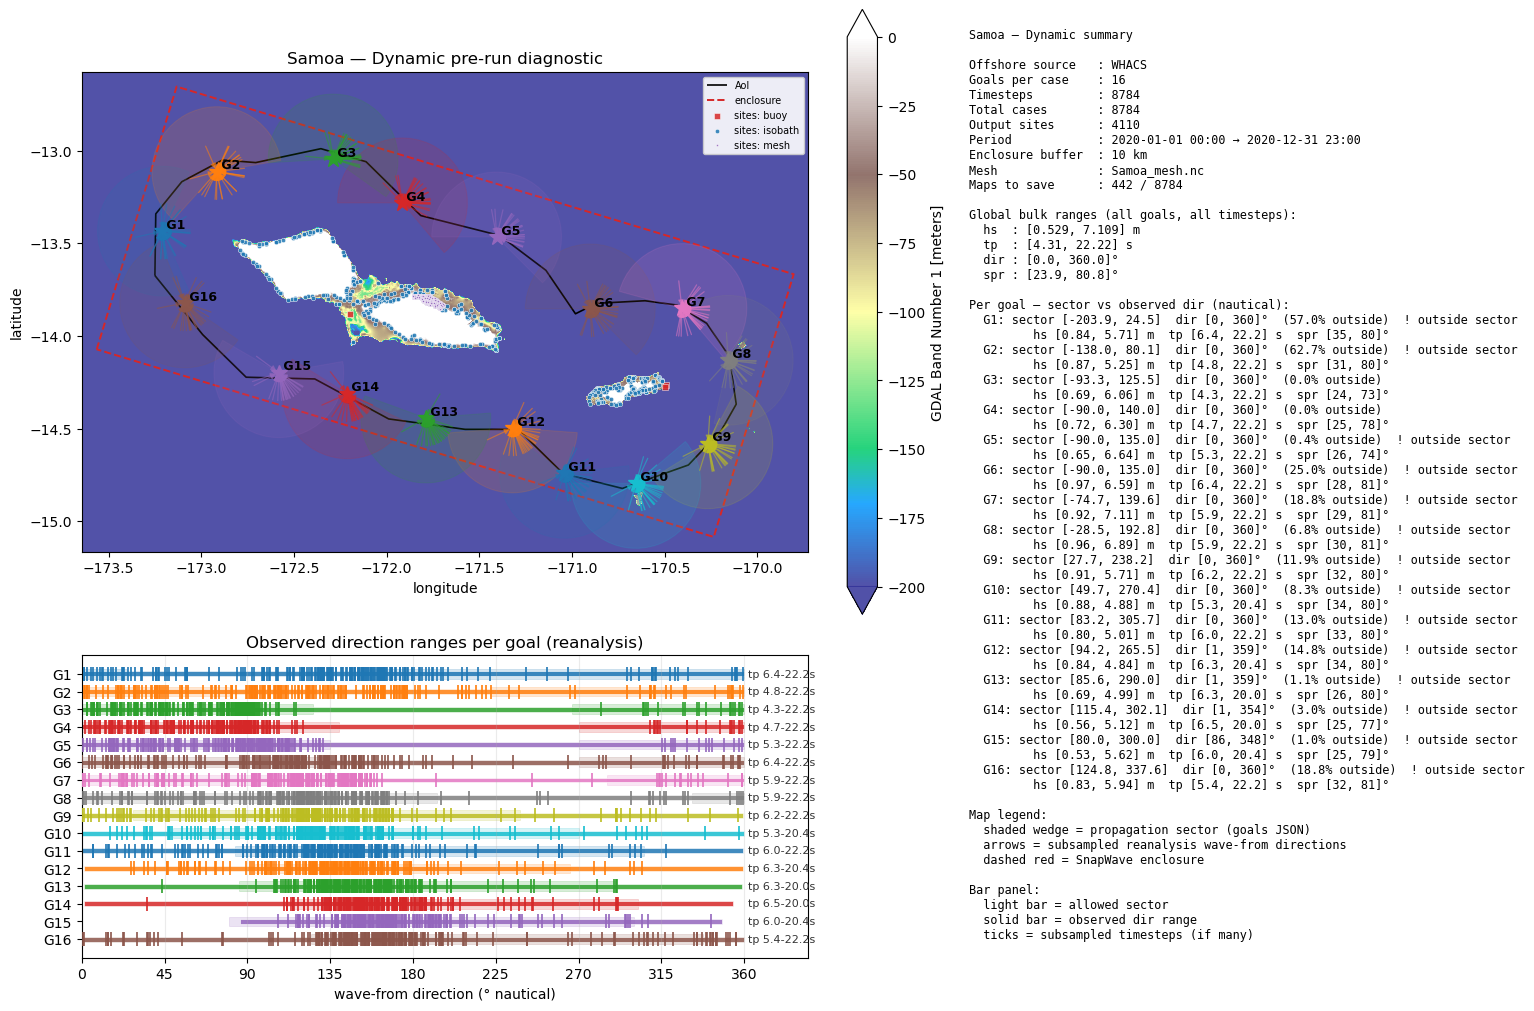

In [7]:
fig = wrapper.plot_configuration(offshore=offshore_ds, offshore_name=offshore_name)
# fig.savefig("dynamic_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.build_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
wrapper.run_cases_in_background(launcher="default", num_workers=1)

In [18]:
wrapper.monitor_cases(value_counts="simple")

Status     
NOT STARTED    8328
FINISHED        455
RUNNING           1
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map when `save_map=True` for that timestep
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

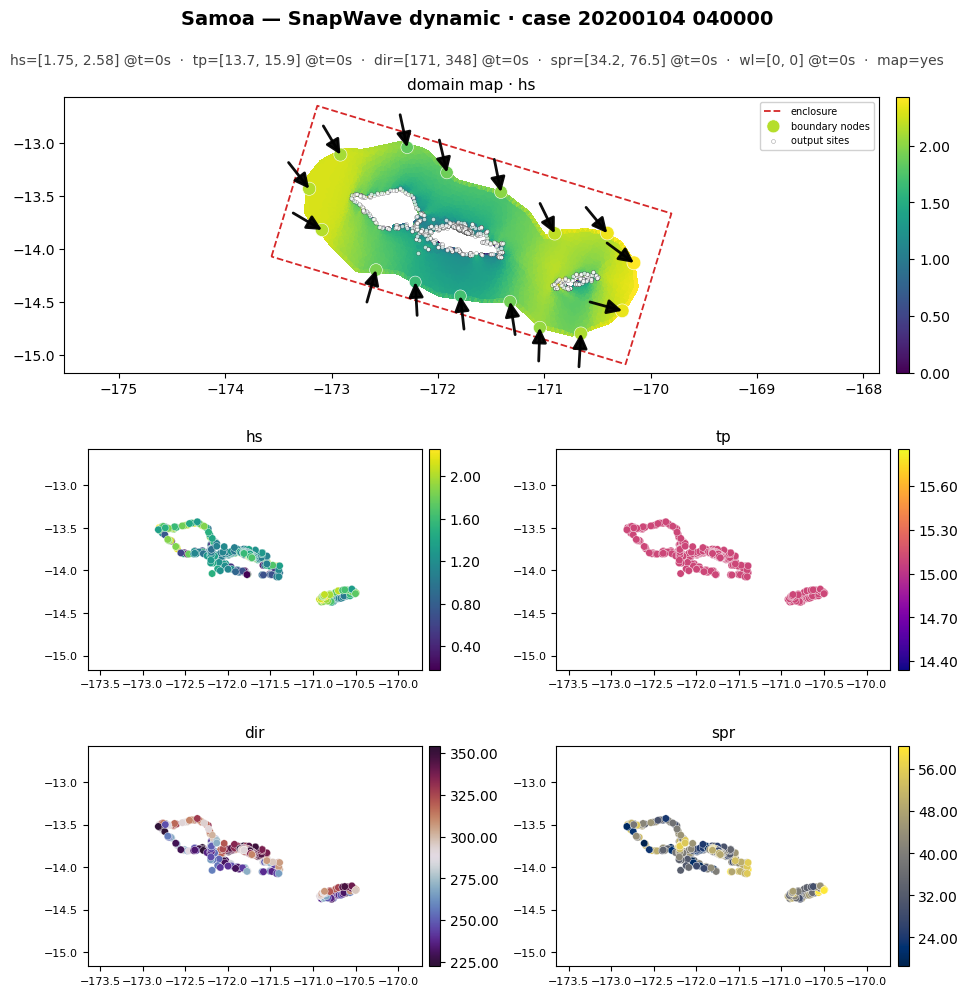

In [10]:
from utils.viz.snapwave_case_plots import CasePlotStyle

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
wrapper.plot_case("SnapWave_CASES_Dynamic/20200104 040000", style=style);

In [11]:
result = wrapper.postprocess_cases()
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_{period.replace('-', '')}.nc"
result.to_netcdf(out_nc)

In [14]:
import xarray as xr

xr.open_dataset(out_nc).load()

<xarray.Dataset> Size: 103MB
Dimensions:         (time: 8784, sites: 728)
Coordinates:
  * time            (time) datetime64[ns] 70kB 2020-01-01 ... 2020-12-31T23:0...
  * sites           (sites) <U24 70kB '5m_0' '5m_1' ... 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 20kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    site_label      (sites) <U5 15kB '5m' '5m' '5m' ... 'waves' 'waves' 'waves'
    site_depth      (sites) float64 6kB -5.0 -5.0 -5.0 ... -80.0 -75.0 -70.0
    site_longitude  (sites) float64 6kB -170.8 -170.7 -170.7 ... -170.5 -170.5
    site_latitude   (sites) float64 6kB -14.36 -14.33 -14.27 ... -14.27 -14.27
Data variables:
    hs              (time, sites) float32 26MB nan 1.689 nan ... 1.265 1.24
    tp              (time, sites) float32 26MB nan 8.661 nan ... 10.99 10.99
    dir             (time, sites) float32 26MB nan 221.5 nan ... 66.68 69.94
    spr             (time, sites) float32 26MB nan 24.98 nan ... 51.27 50.26
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output